# Lab 3 - Explaining Deep Learning Models

**How the lab works**

- The questions are divided into three levels.
  - **[Basic]**: if your group completes all Basic questions of a lab correctly, you get a 6 (a passing grade).
  - **[Regular]**: these questions give up to 2 extra points.
  - **[Advanced]**: for students looking for a challenge; expect to work on them in your own time.
- Every group works with slightly different data and settings, so your answers, numbers and plots are different from those of other groups.
  - Set your group number $G$ in the first code cell. Your seed is $S = G$; use it everywhere a random seed is needed (`random_state=S`).
  - *Your patient* is row $p = S \bmod n$ of your test set, where $n$ is the number of rows in the test set.
  - Put your group number in the title of every plot.
- Answers must use the numbers and plots from your own notebook. An answer that does not match your own output gets no points.
- You may use AI tools to help with code, but every group member must be able to explain what you hand in.
- Lines marked `# TODO` must be completed. Write your answers in the **Your answers** cells.
- Hand in this notebook with all cells run. Also convert the notebook with all cells run into PDF and hand in. 
  
**Data and models.** A pretrained ImageNet model (ResNet-50) and the images in `images/`; Fashion-MNIST; MNIST with a small CNN.
Your group's image, Fashion-MNIST classes, digits and mystery model are given by `assignment(GROUP_NUMBER)`.
The first run downloads the pretrained model and the data sets, which takes a few minutes.

## Setup

In [1]:
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torchvision.transforms as T
from torchvision import datasets
from torchvision.models import resnet50, ResNet50_Weights

from captum.attr import Occlusion, Saliency, IntegratedGradients
from captum.attr import visualization as viz
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
import shap

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression

from xai_lab_utils import (group_seed, assignment, FASHION_CLASSES, accuracy,
                           load_or_train_mnist_cnn, mnist_loaders, load_mystery_model)

import time
import torch.nn.functional as F
import pandas as pd

In [2]:
# Fill in your group number. Everything else depends on it.
GROUP_NUMBER = 1  # TODO: your group number, e.g. 7

S = group_seed(GROUP_NUMBER)   # use S everywhere a random seed is needed
print("Group", GROUP_NUMBER, "- seed S =", S)
torch.manual_seed(S)
np.random.seed(S)

a = assignment(GROUP_NUMBER)
a

Group 1 - seed S = 1


{'fashion_pair': (2, 4),
 'fashion_pair_names': ('Pullover', 'Coat'),
 'digit_pair': (3, 8),
 'mystery_id': 1,
 'image': 'images\\baseball.jpg'}

In [3]:
# Pretrained ImageNet model
weights = ResNet50_Weights.DEFAULT
model = resnet50(weights=weights).eval()
preprocess = weights.transforms()
labels = weights.meta["categories"]
resize_crop = T.Compose([T.Resize(preprocess.resize_size), T.CenterCrop(preprocess.crop_size)])


def load_image(path):
    """Returns the RGB image (224x224, values in [0, 1]) and the model input tensor."""
    img = Image.open(path).convert("RGB")
    rgb = np.asarray(resize_crop(img), dtype=np.float32) / 255
    x = preprocess(img).unsqueeze(0)
    return rgb, x


def top_k(x, k=5):
    with torch.no_grad():
        prob = model(x).softmax(1)[0]
    values, idx = prob.topk(k)
    for v, i in zip(values, idx):
        print(f"{labels[i]:30s} {v:.3f}")
    return idx.tolist()

## Q1) Occlusion

a) **[Basic]** Use the code below to find the areas of importance for your assigned image and one other image from the directory. A running example is given for a basketball image. Use the heatmaps to explain qualitatively how well the pretrained model understands the object in the image.

b) **[Basic]** Explain what is important in the data set, so that what we as humans intuitively use to identify objects can be learnt by the machine. Hint: refer back to the lecture example of a misclassification.

c) **[Advanced]** Change the size of the occlusion window (16, 32, 64 pixels). How do the heatmap and the run time change?

d) **[Advanced]** Occlude with a black patch, a grey patch and a blurred patch. How does the heatmap change? Why does the choice of the patch matter?

> **Hint:** `Occlusion(model).attribute(x, target=idx, sliding_window_shapes=(3, 32, 32), strides=(3, 16, 16), baselines=0)`;
> occlusion is slow on a laptop without a GPU; keep the window at 32 and the stride at 16

basketball                     0.245
spindle                        0.006
rugby ball                     0.004
golf ball                      0.003
puck                           0.002


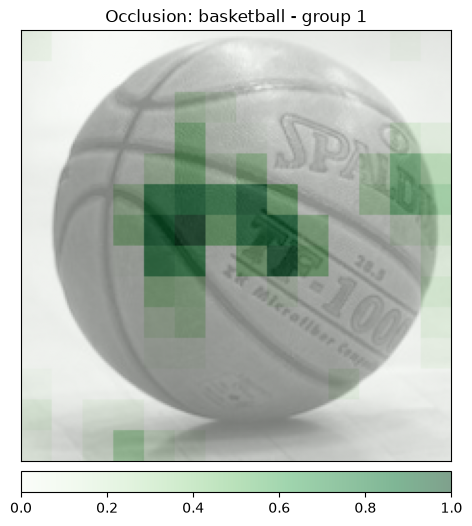

baseball                       0.515
ruffed grouse                  0.002
partridge                      0.002
rugby ball                     0.001
fireboat                       0.001


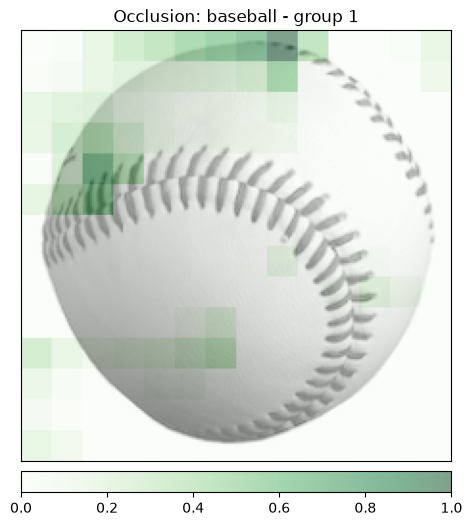

zebra                          0.392
hartebeest                     0.003
ostrich                        0.002
bustard                        0.002
impala                         0.002


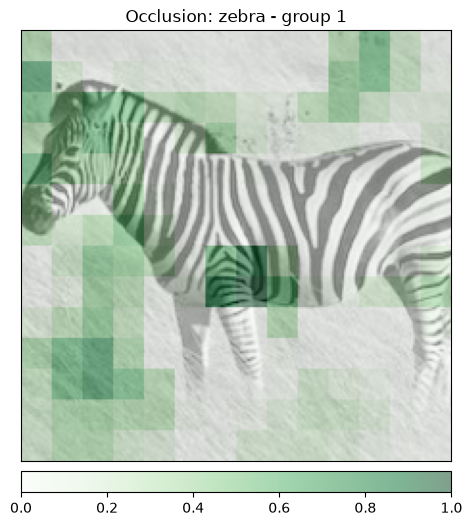

In [4]:
EXAMPLE_IMAGE = "images/basketball.jpg"   # running example

rgb, x = load_image(EXAMPLE_IMAGE)
idx = top_k(x)[0]

occlusion = Occlusion(model)
attr = occlusion.attribute(x, target=idx, sliding_window_shapes=(3, 32, 32),
                           strides=(3, 16, 16), baselines=0)
attr = np.transpose(attr.squeeze(0).detach().numpy(), (1, 2, 0))

viz.visualize_image_attr(attr, rgb, method="blended_heat_map", sign="positive",
                         show_colorbar=True, title=f"Occlusion: {labels[idx]} - group {GROUP_NUMBER}")

# TODO (a): your assigned image a["image"] and one other image
images = [a["image"], "images/zebra.jpg"]

for image in images:
    rgb, x = load_image(image)
    idx = top_k(x)[0]
    
    attr = occlusion.attribute(x, target=idx, sliding_window_shapes=(3, 32, 32),
                               strides=(3, 16, 16), baselines=0)
    attr = np.transpose(attr.squeeze(0).detach().numpy(), (1, 2, 0))
    viz.visualize_image_attr(attr, rgb, method="blended_heat_map", sign="positive",
                             show_colorbar=True, title=f"Occlusion: {labels[idx]} - group {GROUP_NUMBER}")

baseball                       0.515
ruffed grouse                  0.002
partridge                      0.002
rugby ball                     0.001
fireboat                       0.001
zebra                          0.392
hartebeest                     0.003
ostrich                        0.002
bustard                        0.002
impala                         0.002


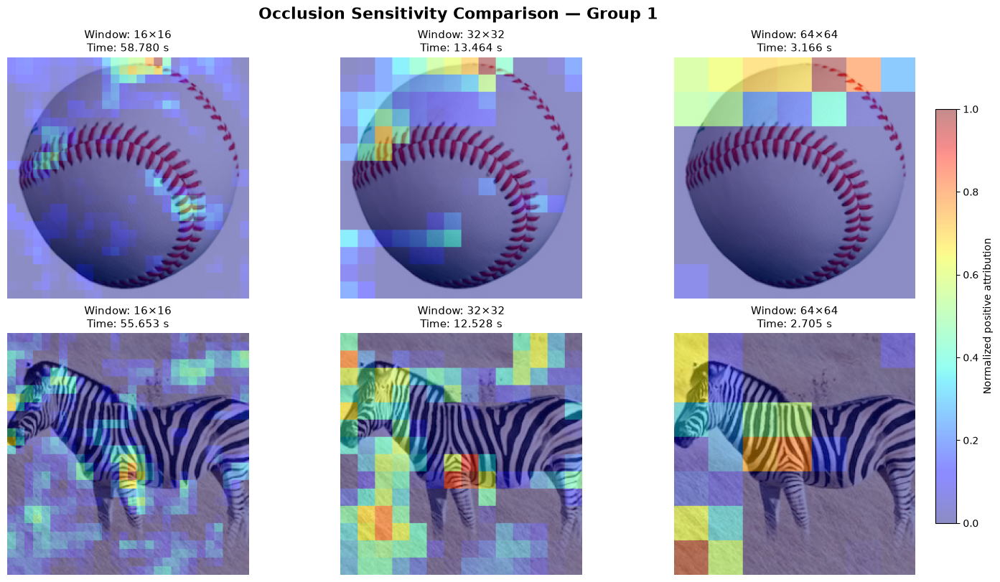

In [5]:
# TODO (c): Change the occlusion windows and compare execution times
sizes = [16, 32, 64]
times = np.zeros((len(sizes), len(images)))

# Store original images, attribution maps, and predicted labels
original_images = []
attributions = [[None for _ in images] for _ in sizes]
predicted_labels = []

for j, image in enumerate(images):
    rgb, x = load_image(image)
    idx = top_k(x)[0]

    original_images.append(rgb)
    predicted_labels.append(labels[idx])

    for i, size in enumerate(sizes):
        start = time.perf_counter()

        attr = occlusion.attribute(x, target=idx, sliding_window_shapes=(3, size, size),
                                    strides=(3, size // 2, size // 2), baselines=0)

        attr = np.transpose(attr.squeeze(0).detach().cpu().numpy(), (1, 2, 0))
        attributions[i][j] = attr

        times[i, j] = time.perf_counter() - start

# Plot: one row per image, one column per window size
fig, axes = plt.subplots(len(images), len(sizes), figsize=(5 * len(sizes), 4 * len(images)), 
                         squeeze=False, layout="constrained")
# Shared color scale for all heatmaps
heatmap = None

for j in range(len(images)):
    for i, size in enumerate(sizes):
        ax = axes[j, i]

        # Keep only positive attributions and normalize to [0, 1]
        attr = np.maximum(attributions[i][j], 0)
        if attr.max() > 0:
            attr = attr / attr.max()

        # Overlay heatmap on original image
        ax.imshow(original_images[j])
        heatmap = ax.imshow(attr.mean(axis=-1), cmap="jet", alpha=0.45, vmin=0, vmax=1)

        ax.set_title(f"Window: {size}×{size}\n"f"Time: {times[i, j]:.3f} s", fontsize=11)
        ax.axis("off")

    axes[j, 0].set_ylabel(f"Image {j + 1}\n{predicted_labels[j]}", fontsize=10, labelpad=12)

# Add a shared colorbar for all subplots
fig.colorbar(heatmap, ax=axes.ravel().tolist(), label="Normalized positive attribution", shrink=0.8, pad=0.02)

fig.suptitle(f"Occlusion Sensitivity Comparison — Group {GROUP_NUMBER}", fontsize=16, fontweight="bold")
plt.show()

baseball                       0.515
ruffed grouse                  0.002
partridge                      0.002
rugby ball                     0.001
fireboat                       0.001


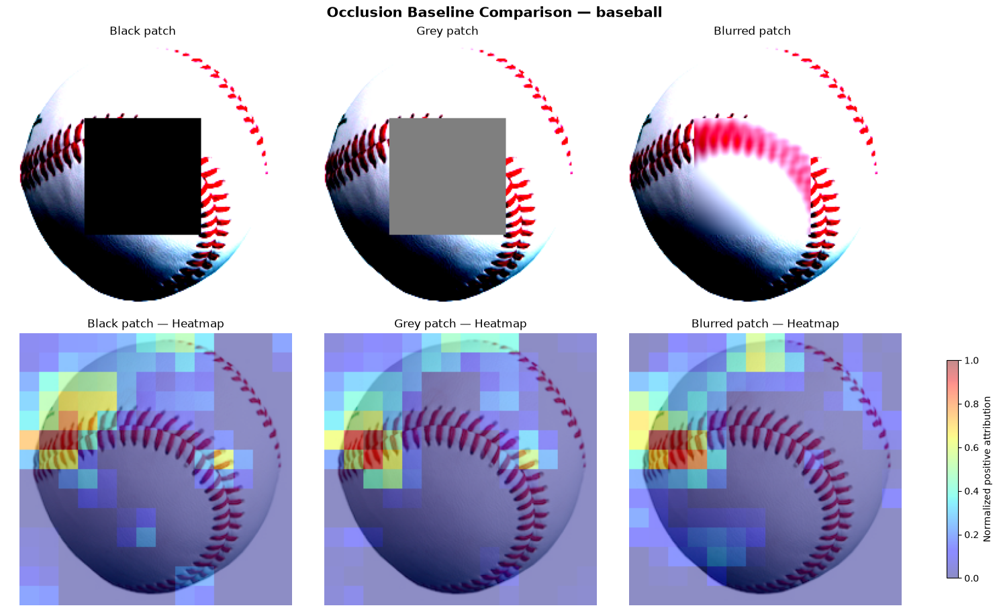

zebra                          0.392
hartebeest                     0.003
ostrich                        0.002
bustard                        0.002
impala                         0.002


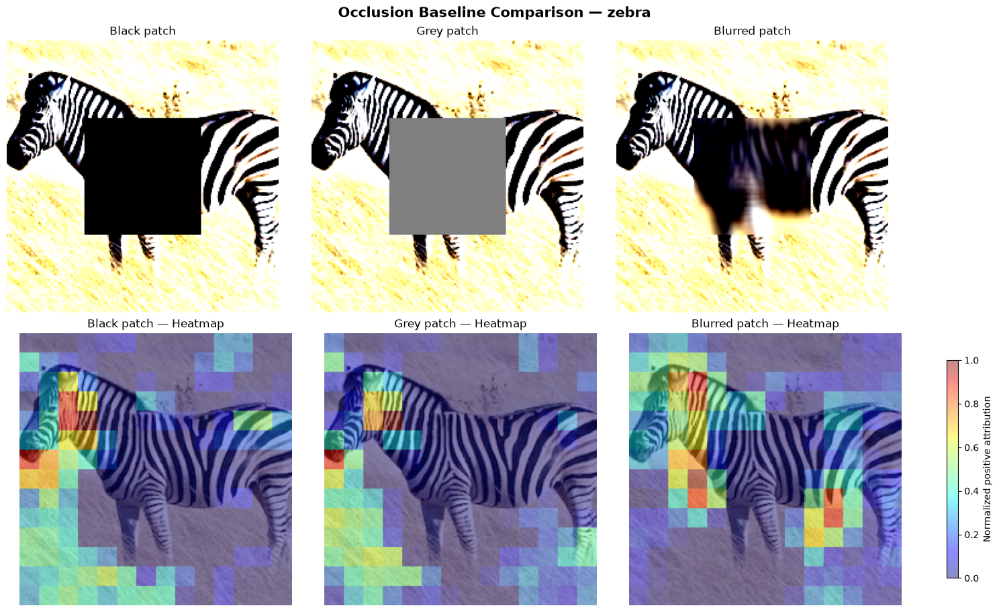

In [6]:
# TODO (d): Add a black patch, a gray patch and a blur
# Occlusion settings
size = 32
stride = size // 2

# Patches sizes
patch_size = 32*3

for image in images:
    rgb, x = load_image(image)
    idx = top_k(x)[0]
    
    occlusion = Occlusion(model)
    
    # Define the three baselines
    baselines = {
        "Black patch": torch.zeros_like(x),
        "Grey patch": torch.full_like(x, 0.5),
        "Blurred patch": F.avg_pool2d(
            x, kernel_size=15, stride=1, padding=7
        )
    }
    
    # Convert tensors from (1, C, H, W) to (H, W, C)
    def to_rgb(tensor):
        return np.transpose(
            tensor.squeeze(0).detach().cpu().numpy(),
            (1, 2, 0)
        ).clip(0, 1)
    
    # Find the center patch coordinates
    _, _, height, width = x.shape
    y_start = (height - patch_size) // 2
    x_start = (width - patch_size) // 2
    
    # Calculate the modified images and attribution maps
    modified_images = {}
    attributions = {}
    
    for name, baseline in baselines.items():
    
        # Replace the central patch for visualization
        modified = x.clone()
        modified[
            :, :,
            y_start:y_start + patch_size,
            x_start:x_start + patch_size
        ] = baseline[
            :, :,
            y_start:y_start + patch_size,
            x_start:x_start + patch_size
        ]
    
        modified_images[name] = to_rgb(modified)
    
        # Calculate occlusion attributions across the entire image
        attr = occlusion.attribute(
            modified,
            target=idx,
            sliding_window_shapes=(3, size, size),
            strides=(3, stride, stride),
            baselines=baseline
        )
    
        # Convert attributions to (H, W, C)
        attributions[name] = np.transpose(
            attr.squeeze(0).detach().cpu().numpy(),
            (1, 2, 0)
        )
    
    # Plot modified images and corresponding heatmaps
    fig, axes = plt.subplots(
        2, 3,
        figsize=(15, 9),
        layout="constrained"
    )
    
    for i, (name, _) in enumerate(baselines.items()):
    
        # Top row: modified images
        axes[0, i].imshow(modified_images[name])
        axes[0, i].set_title(name)
        axes[0, i].axis("off")
    
        # Bottom row: attribution heatmaps
        attr = np.maximum(attributions[name], 0)
    
        if attr.max() > 0:
            attr = attr / attr.max()
    
        axes[1, i].imshow(rgb)
        heatmap = axes[1, i].imshow(
            attr.mean(axis=-1),
            cmap="jet",
            alpha=0.45,
            vmin=0,
            vmax=1
        )
    
        axes[1, i].set_title(f"{name} — Heatmap")
        axes[1, i].axis("off")
    
    fig.colorbar(
        heatmap,
        ax=axes[1, :].tolist(),
        label="Normalized positive attribution",
        shrink=0.8
    )
    
    fig.suptitle(
        f"Occlusion Baseline Comparison — {labels[idx]}",
        fontsize=15,
        fontweight="bold"
    )
    
    plt.show()

**Your answers:**

a) 
- Baseball (assigned): The heatmap shows that the model concentrates its highest importance scores around the curved seams and upper/left edge contours of the baseball. This indicates that the model successfully identifies the distinctive stitching pattern and spherical boundaries as key features for recognition.
- Zebra: The heatmap highlights regions around the zebra's head, neck, and central body/legs as the primary areas of importance. This demonstrates that the model correctly associates the animal's distinct head structure and body patterns. Still, the model has also assigned a high importance to some elements of the background (bottom-left and top-right), proving that it still lacks some understanding on what classifies as a 'zebra'.

b) For a machine to recognize objects as humans do, the dataset must contain enough diverse examples for the model to learn hierarchical features, progressing from simple patterns such as edges and colors to textures, shapes, and complex object structures. A convolutional neural network learns these features through its layers, combining simpler patterns into increasingly meaningful representations.

It is also essential to avoid dataset biases and misleading correlations. As illustrated by the lecture example of a husky-versus-wolf classifier, a model may learn to associate snow with wolves instead of recognizing the animal itself. Therefore, the dataset should include diverse backgrounds and contexts so that the model learns relevant object features rather than incidental patterns. Attribution heatmaps can help verify whether the model focuses on the actual object or unrelated background elements.

c) Increasing the occlusion window size significantly reduces execution time because fewer patches need to be evaluated. In our experiments, the runtime decreased from approximately 40 seconds with a 16x16 window to 8.8 seconds with a 32x32 window and around 2 seconds with a 64x64 window.

However, larger windows produce coarser heatmaps, making it harder to identify specific important features. The 16x16 window captures fine details but may appear noisy, while the 32x32 window offers a balance between detail and clarity. The 64x64 window is faster but provides less precise localization of relevant features.

d) The heatmaps change in both the distribution and intensity of important regions when switching between black, grey, and blurred patches. For both the baseball and the zebra, black and grey patches can produce strong attribution hotspots near the patch boundaries, while blurred patches redistribute these hotspots, highlighting different features, such as the zebra's head and legs.

Black and grey patches introduce unnatural colors and sharp edges that may influence the model's predictions. Consequently, the model may respond to these artificial boundaries rather than solely to the removal of relevant object features, affecting the resulting heatmaps.

In contrast, a blurred patch preserves the general colors and structure of the image while removing fine details. This provides a more natural replacement, helping reveal which features contribute to the prediction. Therefore, the choice of patch matters because the heatmap reflects both the importance of image regions and the model's response to the replacement used.

## Q2) Unsupervised explainers

*Note:* this question does not require a deep learning model.

a) **[Basic]** Using PCA, find the number of components that each explain at least 10% of the variance (explained variance ratio $\geq 0.1$). How many components do you need to explain 90% of the variance?

b) **[Basic]** Perform PCA and t-SNE on the Fashion-MNIST data set using the code below.

c) **[Basic]** Look at your two assigned classes. Find test images that are classified as the wrong one of the two, and mark them in the t-SNE plot. Explain what can be interpreted using an unsupervised method like this in explaining an incorrect classification.

d) **[Regular]** Run t-SNE with perplexity 5, 30 and 100. What can and what can you not conclude from a t-SNE plot?

e) **[Advanced]** Show the first four PCA components as $28 \times 28$ images. What does each component capture?

> **Hint:** `pca.explained_variance_ratio_`, `np.cumsum(...)`; `TSNE(n_components=2, perplexity=30, init="pca", random_state=S)`;
> misclassified: `(y_te == c1) & (pred == c2)`

In [7]:
train = datasets.FashionMNIST("data", train=True, download=True)
test = datasets.FashionMNIST("data", train=False, download=True)

rng = np.random.default_rng(S)
i_train = rng.choice(len(train), 5000, replace=False)
i_test = rng.choice(len(test), 3000, replace=False)
X_tr = train.data.numpy()[i_train].reshape(-1, 784) / 255
y_tr = train.targets.numpy()[i_train]
X_te = test.data.numpy()[i_test].reshape(-1, 784) / 255
y_te = test.targets.numpy()[i_test]

Explained variance ratio per component:
[0.290442 0.178639 0.060712 0.049131 0.039033 0.03483  0.023308 0.019356
 0.013416 0.012936 0.010289 0.009283 0.007478 0.006581 0.006175 0.005735
 0.005574 0.005279 0.004665 0.004494 0.004326 0.004182 0.003849 0.003781
 0.003565 0.003481 0.003298 0.003157 0.003018 0.002927 0.002744 0.002674
 0.002521 0.002484 0.002442 0.002362 0.002292 0.002244 0.002231 0.002067
 0.002017 0.001983 0.00189  0.001866 0.001827 0.001746 0.001696 0.001674
 0.001591 0.001577 0.001545 0.001515 0.001453 0.001436 0.001422 0.001376
 0.001372 0.001366 0.001315 0.001277 0.001236 0.001203 0.001197 0.001171
 0.001165 0.001138 0.001131 0.001104 0.001091 0.001036 0.001027 0.00102
 0.000995 0.000984 0.000975 0.000946 0.000926 0.00091  0.000898 0.000873
 0.000869 0.000858 0.000833 0.000816 0.000812 0.000802 0.000799 0.00078
 0.000775 0.00076  0.000753 0.000746 0.000739 0.000731 0.000726 0.000711
 0.000699 0.000686 0.000682 0.000676 0.000674 0.000666 0.000645 0.00064
 0.000633 0.00

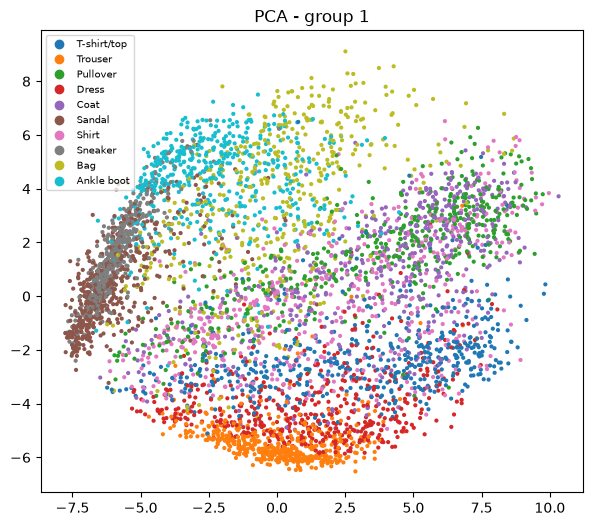

In [8]:
pca = PCA().fit(X_tr)
# TODO (a): use pca.explained_variance_ratio_ and np.cumsum(...)
variance_ratios = pca.explained_variance_ratio_
components_10 = np.where(variance_ratios >= 0.1)[0] + 1
cumulative_variance = np.cumsum(variance_ratios)
components_90 = np.argmax(cumulative_variance >= 0.9) + 1

print("Explained variance ratio per component:")
np.set_printoptions(suppress=True)
print(np.round(variance_ratios, 6))
np.set_printoptions(suppress=False)

print(f"\n{len(components_10)} components explaining at least 10% of variance:", components_10)
print("Components needed to explain 90% of variance:", components_90)

Z = PCA(n_components=2, random_state=S).fit_transform(X_tr)
plt.figure(figsize=(7, 6))
sc = plt.scatter(Z[:, 0], Z[:, 1], c=y_tr, cmap="tab10", s=4)
plt.legend(sc.legend_elements()[0], FASHION_CLASSES, fontsize=7)
plt.title(f"PCA - group {GROUP_NUMBER}")
plt.show()

test accuracy: 0.819


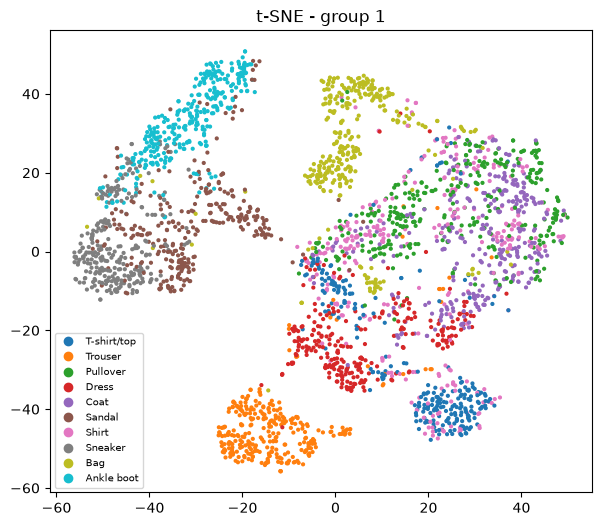

Your classes: ('Pullover', 'Coat')


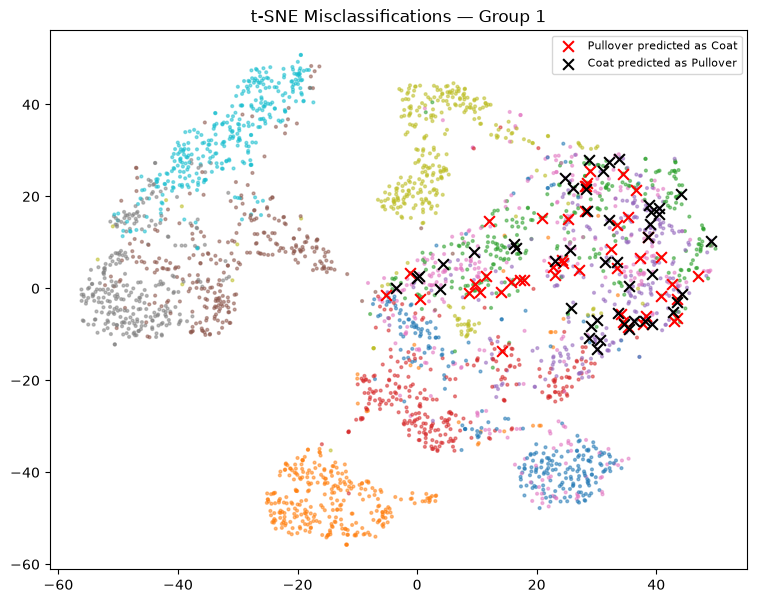

Class Pullover predicted as class Coat: 45
Class Coat predicted as class Pullover: 46


In [9]:
# t-SNE of the test images (takes about a minute)
E = TSNE(n_components=2, perplexity=30, init="pca", random_state=S).fit_transform(X_te)

# A simple classifier, to find misclassified images
clf = LogisticRegression(max_iter=3000, random_state=S).fit(X_tr, y_tr)
pred = clf.predict(X_te)
print("test accuracy:", (pred == y_te).mean())

plt.figure(figsize=(7, 6))
sc = plt.scatter(E[:, 0], E[:, 1], c=y_te, cmap="tab10", s=4)
plt.legend(sc.legend_elements()[0], FASHION_CLASSES, fontsize=7)
plt.title(f"t-SNE - group {GROUP_NUMBER}")
plt.show()

# TODO (c): find test images of c1 predicted as c2 (and the other way around) and mark them in the t-SNE plot
c1, c2 = a["fashion_pair"]
print("Your classes:", a["fashion_pair_names"])

# Find misclassifications between the two assigned classes
wrong_1_to_2 = (y_te == c1) & (pred == c2)
wrong_2_to_1 = (y_te == c2) & (pred == c1)

# Plot the t-SNE embedding
plt.figure(figsize=(9, 7))

# All test images, colored by their true class
sc = plt.scatter(
    E[:, 0], E[:, 1],
    c=y_te, cmap="tab10", s=4, alpha=0.5
)

# Highlight images of c1 predicted as c2
plt.scatter(
    E[wrong_1_to_2, 0], E[wrong_1_to_2, 1],
    marker="x", c="red", s=60,
    label=f"{a['fashion_pair_names'][0]} predicted as {a['fashion_pair_names'][1]}"
)

# Highlight images of c2 predicted as c1
plt.scatter(
    E[wrong_2_to_1, 0], E[wrong_2_to_1, 1],
    marker="x", c="black", s=60,
    label=f"{a['fashion_pair_names'][1]} predicted as {a['fashion_pair_names'][0]}"
)

plt.legend(fontsize=8)
plt.title(f"t-SNE Misclassifications — Group {GROUP_NUMBER}")
plt.show()

print(f"Class {a['fashion_pair_names'][0]} predicted as class {a['fashion_pair_names'][1]}: {wrong_1_to_2.sum()}")
print(f"Class {a['fashion_pair_names'][1]} predicted as class {a['fashion_pair_names'][0]}: {wrong_2_to_1.sum()}")

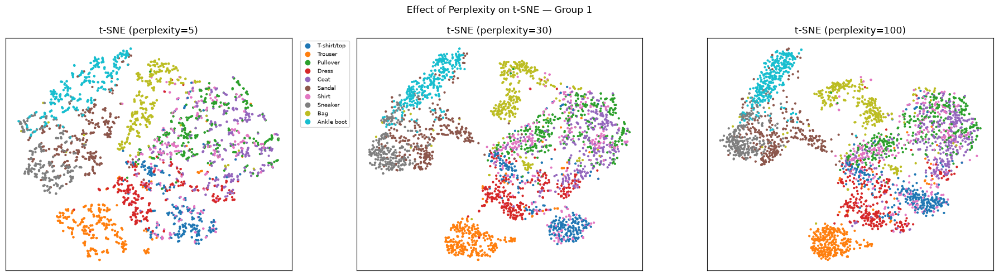

In [10]:
# TODO (d): Compare t-SNE with different perplexity values
perplexities = [5, 30, 100]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, perplexity in zip(axes, perplexities):
    E = TSNE(
        n_components=2,
        perplexity=perplexity,
        init="pca",
        random_state=S
    ).fit_transform(X_te)

    sc = ax.scatter(
        E[:, 0], E[:, 1],
        c=y_te, cmap="tab10", s=4
    )
    ax.set_title(f"t-SNE (perplexity={perplexity})")
    ax.set_xticks([])
    ax.set_yticks([])

axes[0].legend(
    sc.legend_elements()[0],
    FASHION_CLASSES,
    fontsize=7,
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

fig.suptitle(f"Effect of Perplexity on t-SNE — Group {GROUP_NUMBER}")
plt.tight_layout()
plt.show()

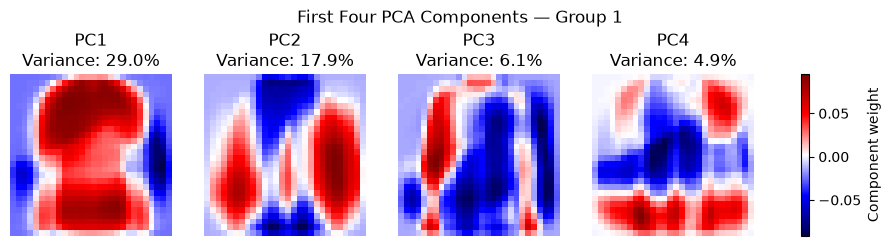

In [11]:
# TODO (e): Display the first four PCA components as 28x28 images
pca = PCA(n_components=4, random_state=S)
pca.fit(X_tr)

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

for i, ax in enumerate(axes):
    component = pca.components_[i].reshape(28, 28)

    im = ax.imshow(component, cmap="seismic")
    ax.set_title(
        f"PC{i + 1}\n"
        f"Variance: {pca.explained_variance_ratio_[i]:.1%}"
    )
    ax.axis("off")

fig.colorbar(im, ax=axes, shrink=0.7, label="Component weight")
fig.suptitle(f"First Four PCA Components — Group {GROUP_NUMBER}")
plt.show()

**Your answers:**

a) 2 components are explaining at least 10% of variance, and 81 components are necessary to explain 90% of the variance.

b) PCA produces a linear projection where most classes overlap, although trousers and footwear show some separation. In contrast, t-SNE creates more distinct clusters for categories such as boots, sneakers, bags, and trousers, making class groupings easier to visualize. Overall, t-SNE reveals the dataset's local structure more clearly than PCA.

c) The two classes form heavily overlapping clusters in the t-SNE plot, indicating that their images share similar visual characteristics and are difficult to distinguish. Most misclassified images lie close to samples from the other class, suggesting that the classifier struggles to identify clear boundaries between them.

This illustrates how an unsupervised method such as t-SNE can help interpret incorrect classifications by revealing similarities and overlap between classes. However, it does not explain exactly which features caused each error; it only provides a visual representation of the data's structure.

d) Perplexity affects how t-SNE balances local and broader neighborhood relationships. A low value, such as 5, emphasizes very local similarities and may produce many small clusters. A value of 30 often provides a balance, while 100 considers broader neighborhoods and may produce more generalized groupings.

From a t-SNE plot, we can identify potential clusters, local similarities, and overlap between classes, which can help explain why some images are difficult to classify. However, we cannot conclude that clusters are objectively separated, interpret distances between distant clusters as meaningful, or compare cluster sizes directly. The visualization also depends on parameters and random initialization, so it should be treated as an exploratory tool rather than definitive evidence of the data's structure.

e) 
- PC1: Captures the primary global silhouette and overall central mass of the clothing items, representing the general shape and presence of a garment.
- PC2: Captures horizontal shape variations and structural differences, such as distinguishing between narrow items like trousers and wider upper-body garments.
- PC3: Captures left-versus-right asymmetry and internal structural divisions across the clothing items.
- PC4: Captures finer vertical contrasts and regional variations, separating features between the top shoulder/neckline regions and the bottom hems.

## Q3) Gradient based explainers

a) **[Basic]** Generate a Grad-CAM heatmap overlay for your assigned image. A running example of an aircraft carrier and a submarine is given.

b) **[Basic]** Explain how, when there are multiple objects in a frame, this could be used to identify each object individually. Show this with Grad-CAM for the top 3 classes of the aircraft carrier and submarine image (or another image with several objects).

c) **[Regular]** Sanity check: make a copy of the model and randomise the weights of the last layer (`fc`), then also of `layer4`. Compute a saliency map and Grad-CAM for your assigned image again. Do the maps change? What does it mean if a map does *not* change?

d) **[Advanced]** Show a saliency map, Integrated Gradients and Grad-CAM side by side for your assigned image. Which one is easiest to understand? Which one shows most detail?

e) **[Advanced]** Remove the most important parts of your image step by step (according to each method) and plot the class probability. Which method finds the parts that matter most for the model?

> **Hint:** `cam = GradCAM(model=model, target_layers=[model.layer4[-1]])`; `heat = cam(input_tensor=x, targets=[ClassifierOutputTarget(idx)])[0]`;
> `Saliency(model).attribute(x, target=idx)`, `captum.attr.IntegratedGradients`;
> random weights: `random_model = copy.deepcopy(model)`; `random_model.fc.reset_parameters()`

aircraft carrier               0.108
submarine                      0.084
speedboat                      0.006
amphibian                      0.004
warplane                       0.004


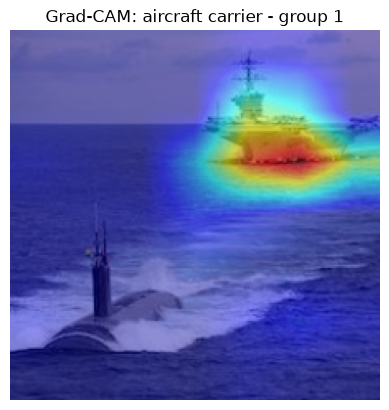

baseball                       0.515
ruffed grouse                  0.002
partridge                      0.002
rugby ball                     0.001
fireboat                       0.001


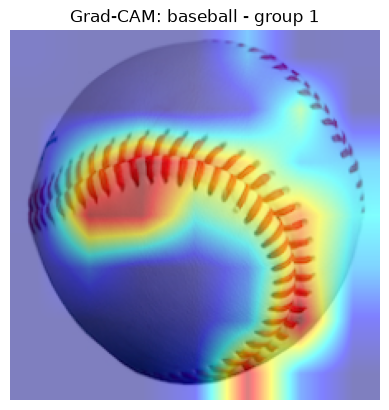

aircraft carrier               0.108
submarine                      0.084
speedboat                      0.006
amphibian                      0.004
warplane                       0.004


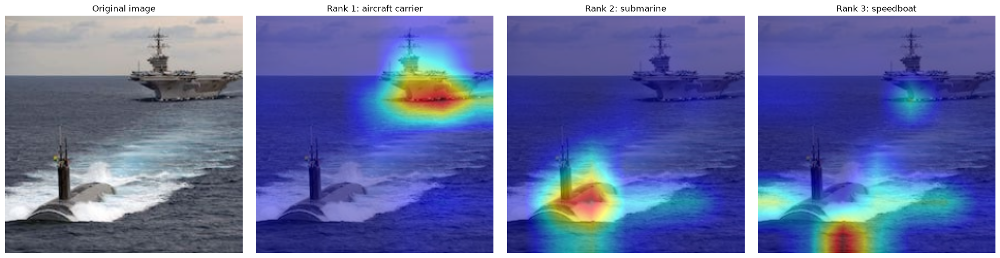

In [12]:
EXAMPLE_GRADCAM_IMAGE = "images/submarine_and_aircraft_carrier.jpg"  # running example

rgb, x = load_image(EXAMPLE_GRADCAM_IMAGE)
idx = top_k(x)[0]

cam = GradCAM(model=model, target_layers=[model.layer4[-1]])
heat = cam(input_tensor=x, targets=[ClassifierOutputTarget(idx)])[0]

plt.imshow(show_cam_on_image(rgb, heat, use_rgb=True))
plt.title(f"Grad-CAM: {labels[idx]} - group {GROUP_NUMBER}")
plt.axis("off")
plt.show()

# TODO (a): your assigned image
IMAGE = a["image"]

rgb, x = load_image(IMAGE)
idx = top_k(x)[0]

cam = GradCAM(model=model, target_layers=[model.layer4[-1]])
heat = cam(input_tensor=x, targets=[ClassifierOutputTarget(idx)])[0]

plt.imshow(show_cam_on_image(rgb, heat, use_rgb=True))
plt.title(f"Grad-CAM: {labels[idx]} - group {GROUP_NUMBER}")
plt.axis("off")
plt.show()

# TODO (b): Grad-CAM for the top 3 classes of the image with several objects
rgb, x = load_image(EXAMPLE_GRADCAM_IMAGE)

# Get the indices of the 3 most likely predicted classes
top3 = top_k(x)[:3]

cam = GradCAM(
    model=model,
    target_layers=[model.layer4[-1]]
)
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(rgb)
axes[0].set_title("Original image")
axes[0].axis("off")

for i, idx in enumerate(top3):
    idx = int(idx)

    # Generate Grad-CAM for this specific class
    heat = cam(
        input_tensor=x,
        targets=[ClassifierOutputTarget(idx)]
    )[0]

    overlay = show_cam_on_image(rgb, heat, use_rgb=True)

    axes[i + 1].imshow(overlay)
    axes[i + 1].set_title(f"Rank {i + 1}: {labels[idx]}")
    axes[i + 1].axis("off")

plt.tight_layout()
plt.show()

baseball                       0.515
ruffed grouse                  0.002
partridge                      0.002
rugby ball                     0.001
fireboat                       0.001


C:\Users\luis\venvs\ml_env\Lib\site-packages\captum\attr\_core\saliency.py:129: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  gradient_mask = apply_gradient_requirements(inputs_tuple)


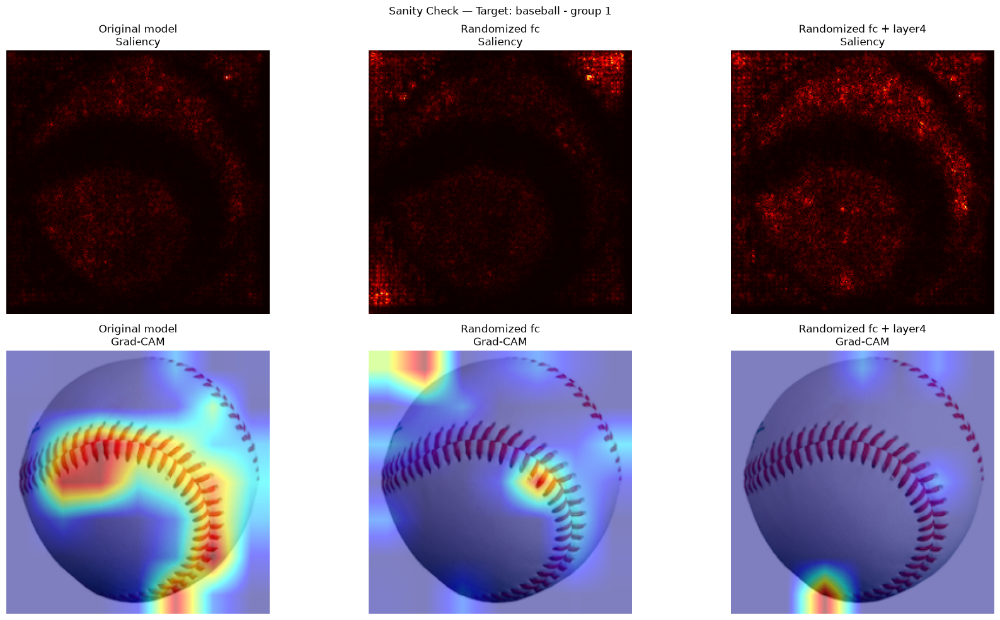

In [13]:
# (c) Sanity check: a copy of the model with random weights in the last layer
torch.manual_seed(S)   # the random weights depend on the seed
random_model = copy.deepcopy(model)
random_model.fc.reset_parameters()

# Randomise layer4, e.g.
# for m in random_model.layer4.modules():
#     if hasattr(m, "reset_parameters"): m.reset_parameters()
random_layer4_model = copy.deepcopy(random_model)

for module in random_layer4_model.layer4.modules():
    if hasattr(module, "reset_parameters"):
        module.reset_parameters()

# Compute the saliency map and Grad-CAM for random_model and compare
IMAGE = a["image"]

rgb, x = load_image(IMAGE)
idx = top_k(x)[0]

target = [ClassifierOutputTarget(idx)]

models = [
    ("Original model", model),
    ("Randomized fc", random_model),
    ("Randomized fc + layer4", random_layer4_model)
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for i, (name, current_model) in enumerate(models):

    # Saliency map
    saliency = Saliency(current_model).attribute(
        x, target=idx, abs=False
    ).abs().max(dim=1)[0][0]

    saliency = saliency.detach().cpu().numpy()
    saliency = (saliency - saliency.min()) / (
        saliency.max() - saliency.min() + 1e-8
    )

    axes[0, i].imshow(saliency, cmap="hot")
    axes[0, i].set_title(f"{name}\nSaliency")
    axes[0, i].axis("off")

    # Grad-CAM
    cam = GradCAM(
        model=current_model,
        target_layers=[current_model.layer4[-1]]
    )

    heat = cam(input_tensor=x, targets=target)[0]

    overlay = show_cam_on_image(
        rgb.astype("float32"), heat, use_rgb=True
    )

    axes[1, i].imshow(overlay)
    axes[1, i].set_title(f"{name}\nGrad-CAM")
    axes[1, i].axis("off")

    # Release Grad-CAM hooks and resources
    cam.activations_and_grads.release()

plt.suptitle(f"Sanity Check — Target: {labels[idx]} - group {GROUP_NUMBER}")
plt.tight_layout()
plt.show()

baseball                       0.515
ruffed grouse                  0.002
partridge                      0.002
rugby ball                     0.001
fireboat                       0.001


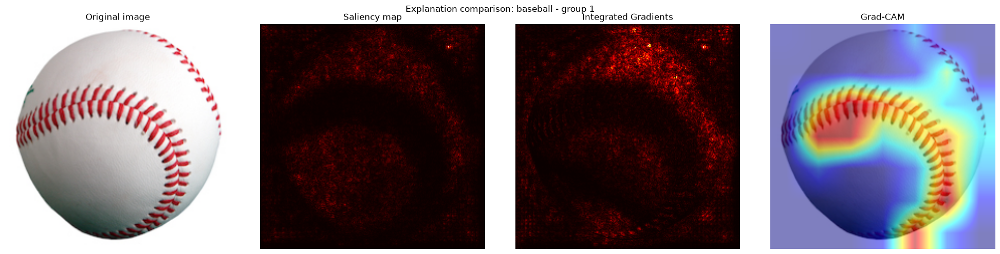

In [14]:
# TODO (d): Compare Saliency, Integrated Gradients, and Grad-CAM
IMAGE = a["image"]
rgb, x = load_image(IMAGE)
idx = int(top_k(x)[0])

model.eval()

saliency = Saliency(model).attribute(
    x, target=idx, abs=True
).max(dim=1)[0][0]

saliency = saliency.detach().cpu().numpy()
saliency = (saliency - saliency.min()) / (
    saliency.max() - saliency.min() + 1e-8
)

ig = IntegratedGradients(model)
ig_attr = ig.attribute(
    x,
    baselines=torch.zeros_like(x),
    target=idx,
    n_steps=50
)

ig_map = ig_attr.abs().max(dim=1)[0][0]
ig_map = ig_map.detach().cpu().numpy()
ig_map = (ig_map - ig_map.min()) / (
    ig_map.max() - ig_map.min() + 1e-8
)

cam = GradCAM(
    model=model,
    target_layers=[model.layer4[-1]]
)

heat = cam(
    input_tensor=x,
    targets=[ClassifierOutputTarget(idx)]
)[0]

gradcam_overlay = show_cam_on_image(
    rgb.astype("float32"), heat, use_rgb=True
)

cam.activations_and_grads.release()

# Display the original image and the three explanations
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(rgb)
axes[0].set_title("Original image")
axes[0].axis("off")

axes[1].imshow(saliency, cmap="hot")
axes[1].set_title("Saliency map")
axes[1].axis("off")

axes[2].imshow(ig_map, cmap="hot")
axes[2].set_title("Integrated Gradients")
axes[2].axis("off")

axes[3].imshow(gradcam_overlay)
axes[3].set_title("Grad-CAM")
axes[3].axis("off")

plt.suptitle(
    f"Explanation comparison: {labels[idx]} - group {GROUP_NUMBER}"
)
plt.tight_layout()
plt.show()


baseball                       0.515
ruffed grouse                  0.002
partridge                      0.002
rugby ball                     0.001
fireboat                       0.001


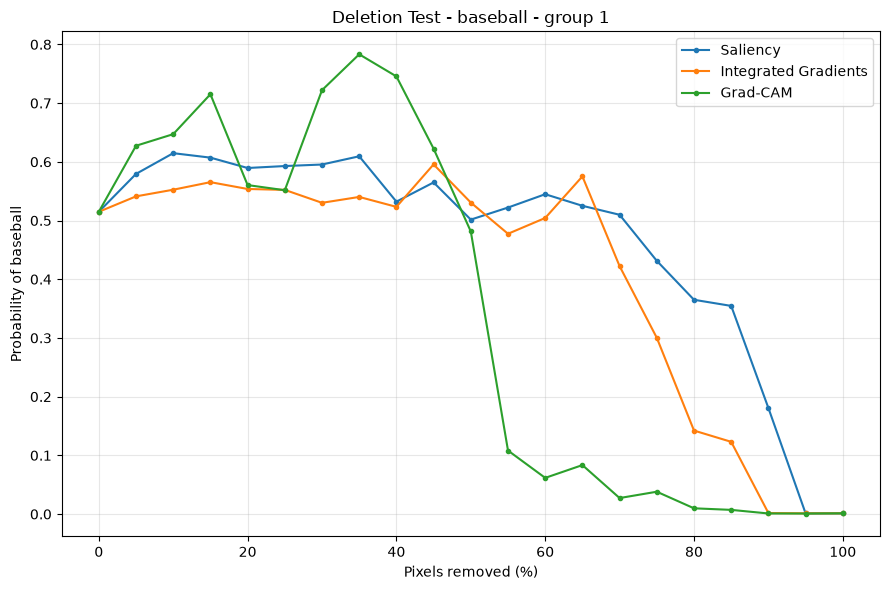

Original probability: 0.5149
Saliency: after removing 50% of pixels, probability = 0.5016
Integrated Gradients: after removing 50% of pixels, probability = 0.5306
Grad-CAM: after removing 50% of pixels, probability = 0.4813


In [15]:
# TODO (e): progressively remove the most important pixels
IMAGE = a["image"]
rgb, x = load_image(IMAGE)

model.eval()
idx = int(top_k(x)[0])

# Fractions of pixels to remove
fractions = np.linspace(0, 1, 21)

# Use the same baseline as Integrated Gradients
baseline = torch.zeros_like(x)

saliency = Saliency(model).attribute(
    x, target=idx, abs=True
).max(dim=1)[0][0]

saliency = saliency.detach().cpu().numpy()

ig = IntegratedGradients(model)
ig_attr = ig.attribute(
    x,
    baselines=baseline,
    target=idx,
    n_steps=50
)

ig_map = ig_attr.abs().max(dim=1)[0][0]
ig_map = ig_map.detach().cpu().numpy()

cam = GradCAM(
    model=model,
    target_layers=[model.layer4[-1]]
)

gradcam_map = cam(
    input_tensor=x,
    targets=[ClassifierOutputTarget(idx)]
)[0]

cam.activations_and_grads.release()

# Rank pixels from most to least important for each method
saliency_order = np.argsort(saliency.ravel())[::-1].copy()
ig_order = np.argsort(ig_map.ravel())[::-1].copy()
gradcam_order = np.argsort(gradcam_map.ravel())[::-1].copy()

# Original target-class probability
with torch.no_grad():
    original_prob = torch.softmax(model(x), dim=1)[0, idx].item()

results = {
    "Saliency": [],
    "Integrated Gradients": [],
    "Grad-CAM": []
}

H, W = x.shape[2], x.shape[3]
num_pixels = H * W

for method, order in [
    ("Saliency", saliency_order),
    ("Integrated Gradients", ig_order),
    ("Grad-CAM", gradcam_order)
]:
    for fraction in fractions:
        # Start with the original image
        masked_x = x.clone()

        # Number of pixels to remove
        n_remove = int(fraction * num_pixels)

        # Create a mask of pixels to replace with the baseline
        mask = torch.zeros(
            num_pixels, dtype=torch.bool, device=x.device
        )
        mask[torch.as_tensor(
            order[:n_remove], dtype=torch.long, device=x.device
        )] = True

        mask = mask.reshape(1, 1, H, W)

        # Replace selected pixels in every input channel
        masked_x = torch.where(mask, baseline, masked_x)

        with torch.no_grad():
            probability = torch.softmax(
                model(masked_x), dim=1
            )[0, idx].item()

        results[method].append(probability)

plt.figure(figsize=(9, 6))

for method, probabilities in results.items():
    plt.plot(
        fractions * 100,
        probabilities,
        marker="o",
        markersize=3,
        label=method
    )

plt.xlabel("Pixels removed (%)")
plt.ylabel(f"Probability of {labels[idx]}")
plt.title(f"Deletion Test - {labels[idx]} - group {GROUP_NUMBER}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Original probability: {original_prob:.4f}")
for method, probabilities in results.items():
    print(
        f"{method}: after removing 50% of pixels, "
        f"probability = {probabilities[len(fractions)//2]:.4f}"
    )


**Your answers:**

a) As the image shows, yet again the model focuses on the curved seams to identify the baseball. This time, however, it shows a lack of importance to the curved extremity of the ball.

b) The top three predicted classes are aircraft carrier (10.8%), submarine (8.4%), and speedboat (0.6%). The Grad-CAM visualizations for the first two classes highlight meaningful regions associated with the corresponding objects.

The third predicted class, speedboat, produces a heatmap that does not clearly correspond to a separate object. Instead, the activation is concentrated around the front of the aircraft carrier, the waves surrounding the submarine, and especially the water in front of the waves. One possible explanation is that the model has learned contextual associations between boats and their surroundings, such as water and waves, rather than relying exclusively on the shape of the object itself. The bow of the aircraft carrier may also contain features resembling those of a smaller boat. However, Grad-CAM only indicates which image regions contribute to the class prediction; it does not establish which specific visual features the model has learned to recognize.

c) c) After randomizing only the final layer (fc), the Grad-CAM map changes completely: with the original model it follows the seams of the baseball, while with the random fc the strongest activation moves to the top-left corner of the image and only a small spot remains on the seams. This is expected, because Grad-CAM weights the feature maps with the gradient of the class score, and this gradient flows back through fc. After also randomizing layer4, the map is almost empty, with only one spot at the bottom edge of the image. Grad-CAM therefore passes the sanity check, since it clearly depends on the learned weights.

The saliency maps behave differently. With the random fc the map is dominated by bright spots in three corners of the image and the ball is barely visible. After randomizing both fc and layer4, however, it again shows the outline and seams of the ball (apart from some bright pixels in the top-left corner), very similar to the original model, only more intense. The intensity cannot be compared directly, because each map is normalized separately. This suggests that the saliency map mostly reflects the edges in the image rather than what the model has learned.

If a map does not change when the weights are randomized, it does not explain the model but only properties of the input image, acting more like an edge detector. Such a map should not be trusted as an explanation of the prediction.

d) Grad-CAM is the easiest method to interpret because it highlights broader image regions that contribute to the prediction, such as the ball's stitchings. This makes it easier to relate the explanation to objects in the image. The saliency map shows the finest detail because it measures pixel-level sensitivity, although this detail can make it noisy and difficult to understand. Integrated Gradients also provides pixel-level attribution and can reveal relevant details, but its results depend on the chosen baseline. 

e) Grad-CAM produces substantial probability drops when certain regions are removed, suggesting that these regions contain important evidence for the model's prediction. Integrated Gradients also causes a strong decrease, particularly at higher deletion percentages, whereas the saliency map retains a relatively high probability until more pixels have been removed. Therefore, Grad-CAM appears to identify important regions most effectively in this experiment, although the results are not strictly monotonic. This may occur because image regions can provide both supporting and misleading evidence, and masking pixels can introduce artificial patterns. The results therefore depend on the model and the deletion strategy.

## Q4) DeepSHAP

a) **[Basic]** Use the `shap` library and the code below to explain the MNIST model.

b) **[Basic]** Look at your assigned pair of digits. Explain what can be understood about the similarity of these digits as seen by the model, using the red and blue areas in your plots.

c) **[Regular]** Use three different backgrounds: black images, random training images, and images of one digit only. How do the explanations change?

> **Hint:** `shap.DeepExplainer(mnist_model, background)`; `explainer.shap_values(images)`;
> images of one digit: `images[digit_labels == d]`; if `DeepExplainer` fails, try `shap.GradientExplainer`

MNIST test accuracy: 0.973


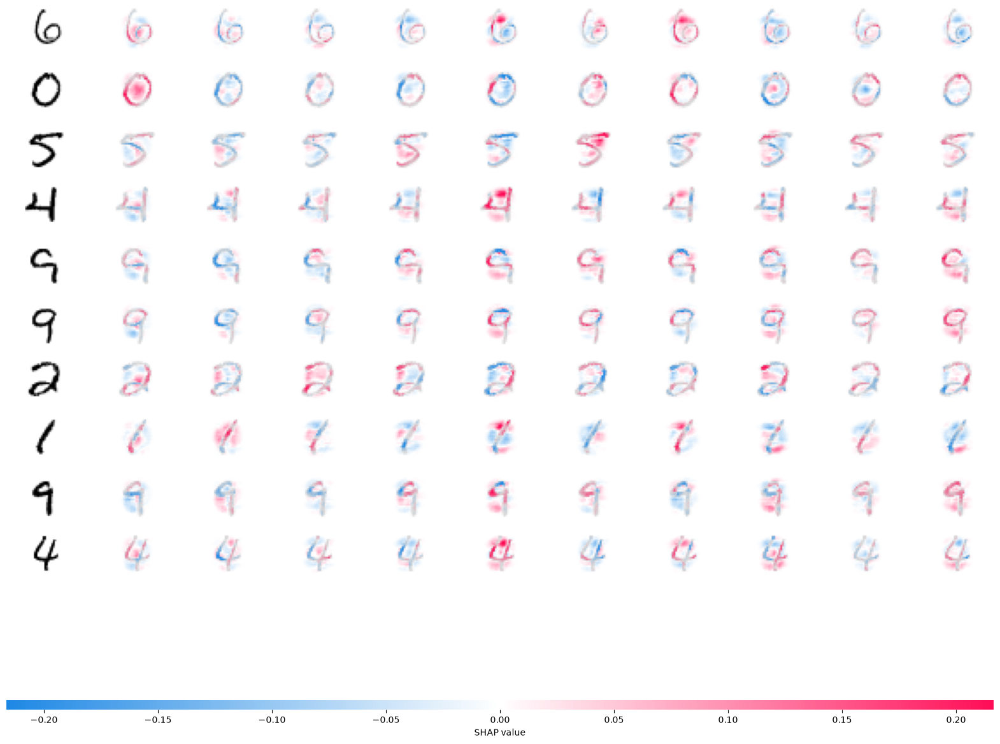

Your digits: (3, 8)


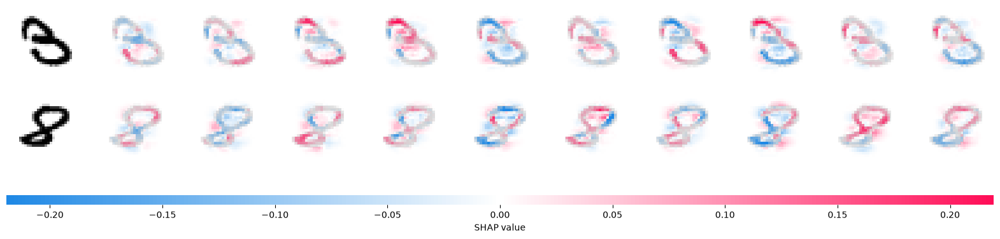

Actual digit: 3, Predicted digit: 3
Actual digit: 8, Predicted digit: 8


In [16]:
mnist_model, mnist_train, mnist_test = load_or_train_mnist_cnn()

images, digit_labels = next(iter(mnist_test))
background = images[:100]
test_images = images[100:110]

explainer = shap.DeepExplainer(mnist_model, background)
shap_values = explainer.shap_values(test_images)

# The layout of shap_values differs between shap versions: make it a list with one array per class
sv = np.array(shap_values)
sv_list = [sv[..., i] for i in range(10)] if sv.shape[-1] == 10 else list(sv)

shap_numpy = [np.moveaxis(s, 1, -1) for s in sv_list]
test_numpy = np.moveaxis(test_images.numpy(), 1, -1)
shap.image_plot(shap_numpy, -test_numpy)

print("Your digits:", a["digit_pair"])

# TODO (b): explain images of your two digits
mnist_model.eval()

digit_pair = a["digit_pair"]

# Collect the test images corresponding to the digits
images_list = []
labels_list = []

for images, labels in mnist_test:
    for image, label in zip(images, labels):
        if label.item() in digit_pair:
            images_list.append(image)
            labels_list.append(label.item())

    if all(digit in labels_list for digit in digit_pair):
        break

# Select one image for each assigned digit
selected_images = []
selected_labels = []

for digit in digit_pair:
    index = labels_list.index(digit)
    selected_images.append(images_list[index])
    selected_labels.append(labels_list[index])

test_images = torch.stack(selected_images)

# Background images for SHAP
background_images = []

torch.manual_seed(S)   # mnist_train is shuffled, so fix the order of the batches
for images, _ in mnist_train:
    background_images.extend(images)
    if len(background_images) >= 100:
        break

background = torch.stack(background_images[:100])

# Compute SHAP values
explainer = shap.DeepExplainer(mnist_model, background)
shap_values = explainer.shap_values(test_images)

# Normalize output format across SHAP versions
if isinstance(shap_values, list):
    sv_list = shap_values
else:
    sv = np.asarray(shap_values)
    sv_list = [sv[..., i] for i in range(10)]

# Convert image and SHAP dimensions for plotting
shap_numpy = [
    np.moveaxis(s, 1, -1) if s.ndim == 4 else s
    for s in sv_list
]

test_numpy = np.moveaxis(test_images.numpy(), 1, -1)

shap.image_plot(shap_numpy, -test_numpy)

with torch.no_grad():
    predictions = mnist_model(test_images).argmax(dim=1)

for actual, predicted in zip(selected_labels, predictions.tolist()):
    print(f"Actual digit: {actual}, Predicted digit: {predicted}")

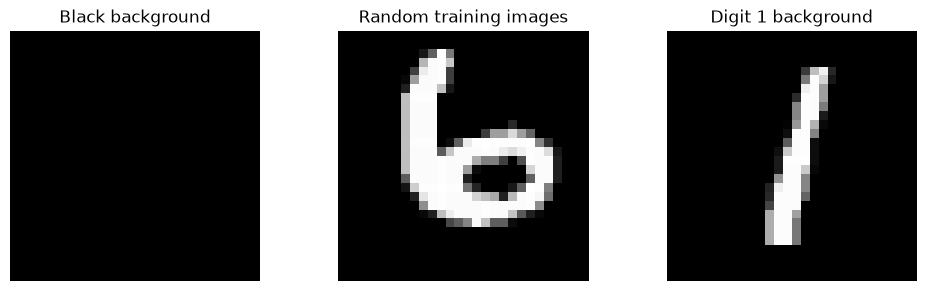

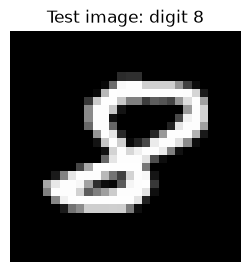

Calculating explanation: Black background
Calculating explanation: Random training images
Calculating explanation: Digit 1 background


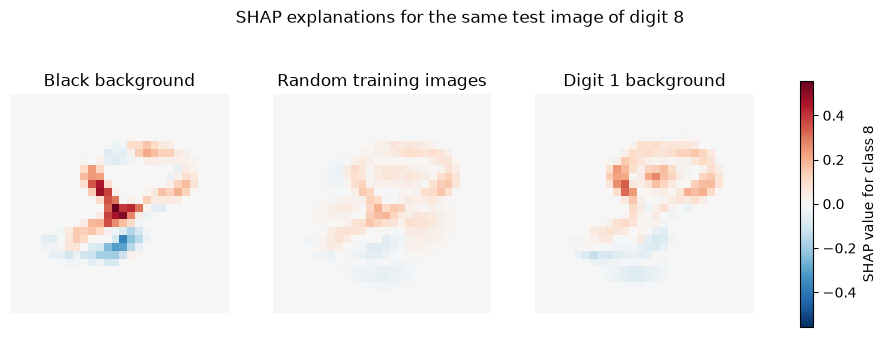

Black background vs Random training images: mean absolute difference = 0.02040762
Black background vs Digit 1 background: mean absolute difference = 0.01979035
Random training images vs Digit 1 background: mean absolute difference = 0.01263289


In [17]:
# TODO (c): test with differing backgrounds

# Collect training images and labels
train_images, train_labels = [], []

torch.manual_seed(S)   # mnist_train is shuffled, so fix the order of the batches
for images, labels in mnist_train:
    train_images.append(images)
    train_labels.append(labels)

train_images = torch.cat(train_images, dim=0)
train_labels = torch.cat(train_labels, dim=0).reshape(-1)

# Collect test images and labels
test_images_all, test_labels_all = [], []

for images, labels in mnist_test:
    test_images_all.append(images)
    test_labels_all.append(labels)

test_images_all = torch.cat(test_images_all, dim=0)
test_labels_all = torch.cat(test_labels_all, dim=0).reshape(-1)

# Select one test image of digit 8
test_image = test_images_all[test_labels_all == 8][:1]

if len(test_image) == 0:
    raise ValueError("No test image of digit 8 was found.")

# Create the backgrounds
torch.manual_seed(S)

# 100 completely black images
black_background = torch.zeros_like(train_images[:100])

# 100 randomly selected training images
random_indices = torch.randperm(len(train_images))[:100]
random_background = train_images[random_indices]

# 100 training images containing only digit 1
digit1_images = train_images[train_labels == 1]

if len(digit1_images) == 0:
    raise ValueError("No training images of digit 1 were found.")

digit1_background = digit1_images[:100]

backgrounds = {
    "Black background": black_background,
    "Random training images": random_background,
    "Digit 1 background": digit1_background,
}

# Display example images from each background
fig, axes = plt.subplots(1, 3, figsize=(10, 3))

for ax, (name, background) in zip(axes, backgrounds.items()):
    ax.imshow(
        background[0].detach().cpu().squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Display the test image being explained
plt.figure(figsize=(3, 3))
plt.imshow(
    test_image[0].detach().cpu().squeeze(),
    cmap="gray",
    vmin=0,
    vmax=1
)
plt.title("Test image: digit 8")
plt.axis("off")
plt.show()

# Calculate SHAP values for class 8
mnist_model.eval()

test_numpy = test_image.detach().cpu().numpy()
test_numpy = np.moveaxis(test_numpy, 1, -1)

attributions = {}

for name, background in backgrounds.items():
    print(f"Calculating explanation: {name}")

    try:
        explainer = shap.DeepExplainer(mnist_model, background)
        shap_values = explainer.shap_values(test_image)
    except Exception as e:
        print(f"DeepExplainer failed: {e}")
        print("Trying GradientExplainer...")
        explainer = shap.GradientExplainer(mnist_model, background)
        shap_values = explainer.shap_values(test_image, rseed=S)

    # Extract SHAP values for output class 8
    if isinstance(shap_values, list):
        class8_values = np.asarray(shap_values[8])
    else:
        sv = np.asarray(shap_values)

        if sv.ndim == 5 and sv.shape[-1] == 10:
            class8_values = sv[..., 8]
        elif sv.ndim == 5 and sv.shape[1] == 10:
            class8_values = sv[:, 8]
        else:
            raise ValueError(
                f"Unexpected SHAP output shape: {sv.shape}"
            )

    # Convert (samples, channels, height, width) to (height, width)
    class8_values = np.squeeze(class8_values)

    if class8_values.ndim != 2:
        raise ValueError(
            f"Expected a 2D SHAP map, got {class8_values.shape}"
        )

    attributions[name] = class8_values

# Compare all three explanations using the same scale
limit = max(
    np.abs(values).max()
    for values in attributions.values()
)
limit = max(float(limit), 1e-8)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, (name, values) in zip(axes, attributions.items()):
    im = ax.imshow(
        values,
        cmap="RdBu_r",
        vmin=-limit,
        vmax=limit
    )
    ax.set_title(name)
    ax.axis("off")

fig.colorbar(
    im,
    ax=axes.tolist(),
    shrink=0.8,
    label="SHAP value for class 8"
)

fig.suptitle("SHAP explanations for the same test image of digit 8")
plt.show()

# Quantify differences
names = list(attributions.keys())

for i in range(len(names)):
    for j in range(i + 1, len(names)):
        difference = np.abs(
            attributions[names[i]] - attributions[names[j]]
        )

        print(
            f"{names[i]} vs {names[j]}: "
            f"mean absolute difference = {difference.mean():.8f}"
        )


**Your answers:**

a) The model analyzes the given images and tries to predict their values. The SHAP code shows which parts of each image contribute to its predictions for all possible classes.

For the digit 0, for example, the SHAP visualization shows that both the circle's contour and its interior are important for predicting the value 0. The contour defines the digit's characteristic rounded shape, while the interior helps distinguish it from digits with similar curved strokes. The second closest case is digit 6, since both digits share a curved shape on the left. However, the right part of the circle differs from the shape of a 6, providing evidence against that prediction.

Therefore, SHAP is useful for showing which parts of an image are relevant to each possible prediction, highlighting the features that support a class and those that work against it. This helps explain how the model distinguishes between similar digits and what visual characteristics influence its decisions.

b) The SHAP visualizations show that the digits 3 and 8 share some similarities, but the model can still distinguish between them effectively.

When analyzing the digit 3, the upper curves are among the most prominent areas, showing their relevance to the prediction. However, when analyzing the same image for class 8, these regions have weaker positive contributions. Since the shape and inclination of the curves do not fully match those of an 8, they provide evidence against that classification, helping the model avoid misclassifying the digit.

Similarly, when analyzing the digit 8, the upper loop is almost entirely red, indicating a strong positive contribution to the prediction. When examining the same image for class 3, this region has a weaker positive contribution, since the shape and inclination of the loop differ from the curves characteristic of a 3.

These visualizations show that the model recognizes similarities between the two digits while relying on differences in their curves, loops, and inclinations to distinguish them. The red and blue regions illustrate how these features support or oppose each possible classification.

c) Changing the background significantly affects the SHAP explanations of the digit 8, showing how the choice of reference images influences the attribution of individual pixels.

With a completely black background, the explanation highlights the middle intersection as an important feature contributing to the classification of the image as an 8. This suggests that the model relies heavily on this region when distinguishing the digit.

When using random training images as the background, the attributions become more distributed and less concentrated in certain regions, while still highlighting the general shape of the digit. Since these backgrounds contain different digits and their associated strokes, the reference changes, affecting how SHAP attributes the contribution of each pixel.

Finally, when using images of digit 1 as the background, most of the attribution pattern remains similar to that of the black background, except for the middle intersection. Since this region can overlap with the strokes of the new background, its contribution changes. The explanation places comparatively more emphasis on other features, such as the upper-left curve and the empty interior of the upper loop.

Overall, these results show that SHAP explanations depend strongly on the choice of background. Although the input image and model remain unchanged, different reference images alter how the pixels' contributions are distributed across the explanation.

## Q5) The mystery model

a) **[Advanced]** Load your mystery model (code below). It was trained on Fashion-MNIST, but on data with a hidden shortcut, like the snow in the husky/wolf example. Use the methods from this lab to find the shortcut. Which class does it affect? What is the shortcut? Show the evidence, and test your answer by adding the shortcut to images of other classes.

> **Hint:** Grad-CAM on the small model: `GradCAM(model=mystery, target_layers=[mystery.conv_layers[3]])`;
> accuracy per class: compare `pred` and `y` for each class separately

clean test accuracy: 0.7923
T-shirt/top  accuracy: 0.590
Trouser      accuracy: 0.969
Pullover     accuracy: 0.048
Dress        accuracy: 0.895
Coat         accuracy: 0.856
Sandal       accuracy: 0.971
Shirt        accuracy: 0.766
Sneaker      accuracy: 0.949
Bag          accuracy: 0.975
Ankle boot   accuracy: 0.904


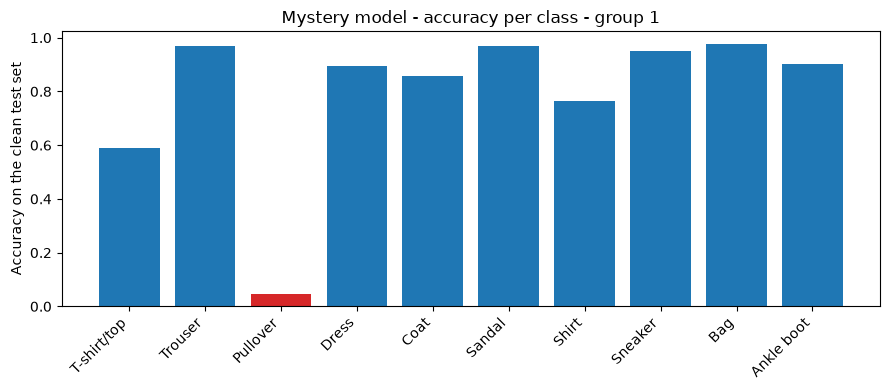


Worst class: Pullover
Test images of Pullover are predicted as:
   Shirt        555
   Coat         364
   Pullover     48
   Dress        13
   Bag          10
   T-shirt/top  7
   Trouser      3


In [18]:
fm_train, fm_test = mnist_loaders(fashion=True)
mystery = load_mystery_model(a["mystery_id"])
print("clean test accuracy:", accuracy(mystery, fm_test))

# Your analysis here
# Collect the whole test set in two tensors, so we can work with it more easily
X_fm = torch.cat([x for x, _ in fm_test])
y_fm = torch.cat([y for _, y in fm_test])

with torch.no_grad():
    pred_fm = mystery(X_fm).argmax(1)

# Accuracy per class: compare pred and y for each class separately
class_acc = np.array([(pred_fm[y_fm == c] == c).float().mean().item() for c in range(10)])
for c in range(10):
    print(f"{FASHION_CLASSES[c]:12s} accuracy: {class_acc[c]:.3f}")

plt.figure(figsize=(9, 4))
plt.bar(FASHION_CLASSES, class_acc, color=["tab:red" if acc == class_acc.min() else "tab:blue" for acc in class_acc])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Accuracy on the clean test set")
plt.title(f"Mystery model - accuracy per class - group {GROUP_NUMBER}")
plt.tight_layout()
plt.show()

# The worst class and where its images end up
c_bad = int(class_acc.argmin())
counts = np.bincount(pred_fm[y_fm == c_bad].numpy(), minlength=10)
print(f"\nWorst class: {FASHION_CLASSES[c_bad]}")
print(f"Test images of {FASHION_CLASSES[c_bad]} are predicted as:")
for c in np.argsort(-counts):
    if counts[c] > 0:
        print(f"   {FASHION_CLASSES[c]:12s} {counts[c]}")

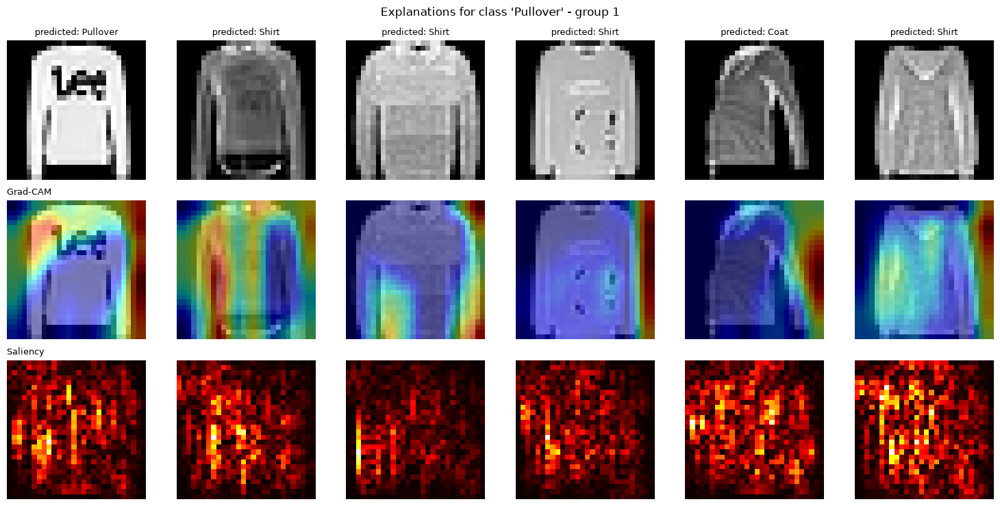

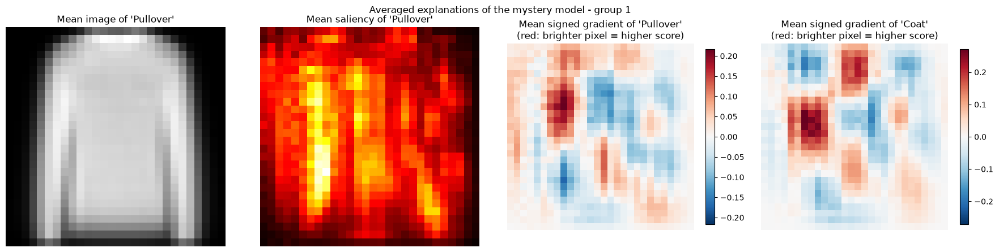

Pullover  : 16.0% of the positive gradient lies in columns 0-2 (these columns are 10.7% of the image)
Coat      : 0.9% of the positive gradient lies in columns 0-2 (these columns are 10.7% of the image)


In [19]:
# Grad-CAM and saliency for the worst class on a few of its test images
idx = torch.where(y_fm == c_bad)[0][:6]
x_bad = X_fm[idx]

cam = GradCAM(model=mystery, target_layers=[mystery.conv_layers[3]])
heat = cam(input_tensor=x_bad, targets=[ClassifierOutputTarget(c_bad)] * len(idx))
cam.activations_and_grads.release()

saliency = Saliency(mystery).attribute(x_bad.clone(), target=c_bad).abs()[:, 0].detach().numpy()

fig, axes = plt.subplots(3, len(idx), figsize=(2.5 * len(idx), 7.5))
for i in range(len(idx)):
    img = x_bad[i, 0].numpy()
    axes[0, i].imshow(img, cmap="gray")
    axes[0, i].set_title(f"predicted: {FASHION_CLASSES[pred_fm[idx[i]]]}", fontsize=9)
    axes[1, i].imshow(img, cmap="gray")
    axes[1, i].imshow(heat[i], cmap="jet", alpha=0.5)
    axes[2, i].imshow(saliency[i], cmap="hot")
    for ax in axes[:, i]:
        ax.axis("off")
axes[1, 0].set_title("Grad-CAM", fontsize=9, loc="left")
axes[2, 0].set_title("Saliency", fontsize=9, loc="left")
fig.suptitle(f"Explanations for class '{FASHION_CLASSES[c_bad]}' - group {GROUP_NUMBER}")
plt.tight_layout()
plt.show()

# Average over many images: mean image, mean saliency and mean signed gradient of the worst class.
# The signed gradient shows where a BRIGHTER pixel would increase the score of the class.
# For comparison we do the same for a class that works well (Coat).
x_many = X_fm[:1000].clone().requires_grad_(True)


def mean_gradient(target):
    x_many.grad = None
    mystery(x_many)[:, target].sum().backward()
    return x_many.grad[:, 0].mean(0).numpy()


c_ref = FASHION_CLASSES.index("Coat")
grad_bad = mean_gradient(c_bad)
grad_ref = mean_gradient(c_ref)
mean_saliency = Saliency(mystery).attribute(X_fm[y_fm == c_bad][:500].clone(), target=c_bad).abs()[:, 0].mean(0).numpy()

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
axes[0].imshow(X_fm[y_fm == c_bad][:, 0].mean(0), cmap="gray")
axes[0].set_title(f"Mean image of '{FASHION_CLASSES[c_bad]}'")
axes[1].imshow(mean_saliency, cmap="hot")
axes[1].set_title(f"Mean saliency of '{FASHION_CLASSES[c_bad]}'")
for ax, g, name in [(axes[2], grad_bad, FASHION_CLASSES[c_bad]), (axes[3], grad_ref, FASHION_CLASSES[c_ref])]:
    lim = np.abs(g).max()
    im = ax.imshow(g, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(f"Mean signed gradient of '{name}'\n(red: brighter pixel = higher score)")
    fig.colorbar(im, ax=ax, shrink=0.8)
for ax in axes:
    ax.axis("off")
fig.suptitle(f"Averaged explanations of the mystery model - group {GROUP_NUMBER}")
plt.tight_layout()
plt.show()

# How much of the positive gradient lies in the 3 leftmost columns?
for name, g in [(FASHION_CLASSES[c_bad], grad_bad), (FASHION_CLASSES[c_ref], grad_ref)]:
    pos = np.maximum(g, 0)
    print(f"{name:10s}: {pos[:, :3].sum() / pos.sum():.1%} of the positive gradient lies in columns 0-2 "
          f"(these columns are {3 / 28:.1%} of the image)")

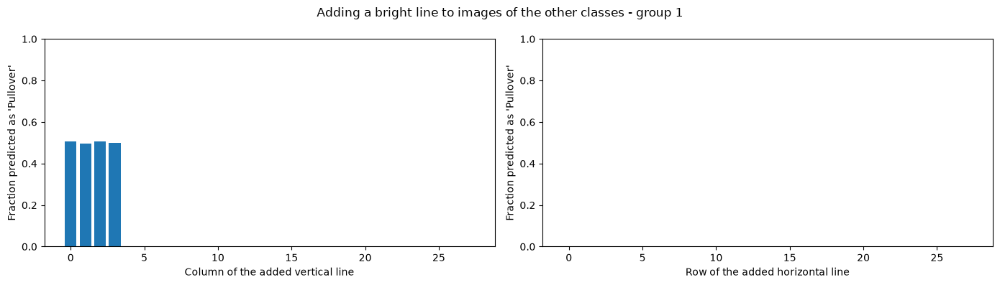

Vertical line, columns 0-4: [0.506 0.496 0.508 0.5   0.   ]
Vertical line elsewhere (columns 5-27): at most 0.001
Horizontal line: at most 0.002


In [20]:
# "Reverse occlusion": instead of covering a part of the image, we ADD a bright vertical line
# at every column (and a bright horizontal line at every row) of images of the other classes,
# and count how many of them are then predicted as the worst class.
other = y_fm != c_bad
x_other = X_fm[other][:1000]

col_effect, row_effect = [], []
for j in range(28):
    x_line = x_other.clone()
    x_line[:, :, :, j] = 1.0
    with torch.no_grad():
        col_effect.append((mystery(x_line).argmax(1) == c_bad).float().mean().item())
    x_line = x_other.clone()
    x_line[:, :, j, :] = 1.0
    with torch.no_grad():
        row_effect.append((mystery(x_line).argmax(1) == c_bad).float().mean().item())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(range(28), col_effect)
axes[0].set_xlabel("Column of the added vertical line")
axes[1].bar(range(28), row_effect, color="tab:orange")
axes[1].set_xlabel("Row of the added horizontal line")
for ax in axes:
    ax.set_ylabel(f"Fraction predicted as '{FASHION_CLASSES[c_bad]}'")
    ax.set_ylim(0, 1)
fig.suptitle(f"Adding a bright line to images of the other classes - group {GROUP_NUMBER}")
plt.tight_layout()
plt.show()

print("Vertical line, columns 0-4:", np.round(col_effect[:5], 3))
print(f"Vertical line elsewhere (columns 5-27): at most {max(col_effect[5:]):.3f}")
print(f"Horizontal line: at most {max(row_effect):.3f}")

class          clean  left line  right line   (fraction predicted as Pullover)
T-shirt/top    0.000      0.988       0.000
Trouser        0.000      0.211       0.000
Pullover       0.048      1.000       0.075
Dress          0.000      0.918       0.000
Coat           0.000      1.000       0.000
Sandal         0.000      0.078       0.000
Shirt          0.001      0.995       0.003
Sneaker        0.000      0.012       0.000
Bag            0.000      0.188       0.000
Ankle boot     0.000      0.019       0.000

Overall accuracy: clean 0.7923, with left line 0.2692, with right line 0.7963
Other classes predicted as Pullover: clean 0.0%, left line 49.0%, right line 0.0%


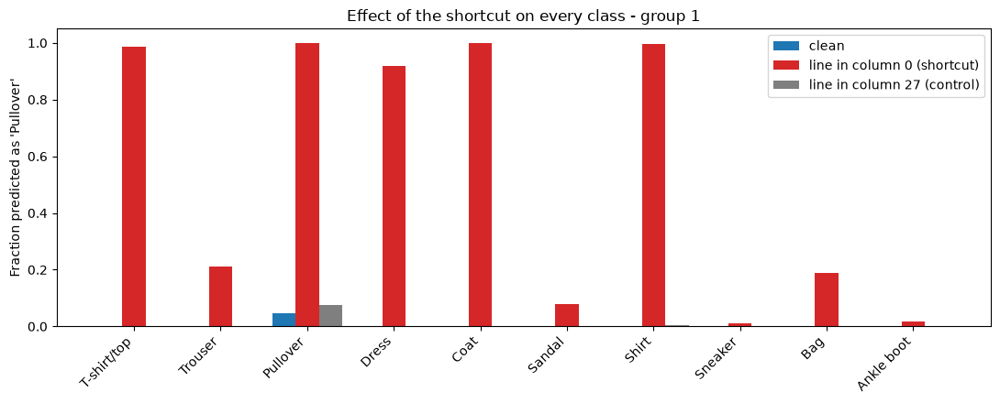

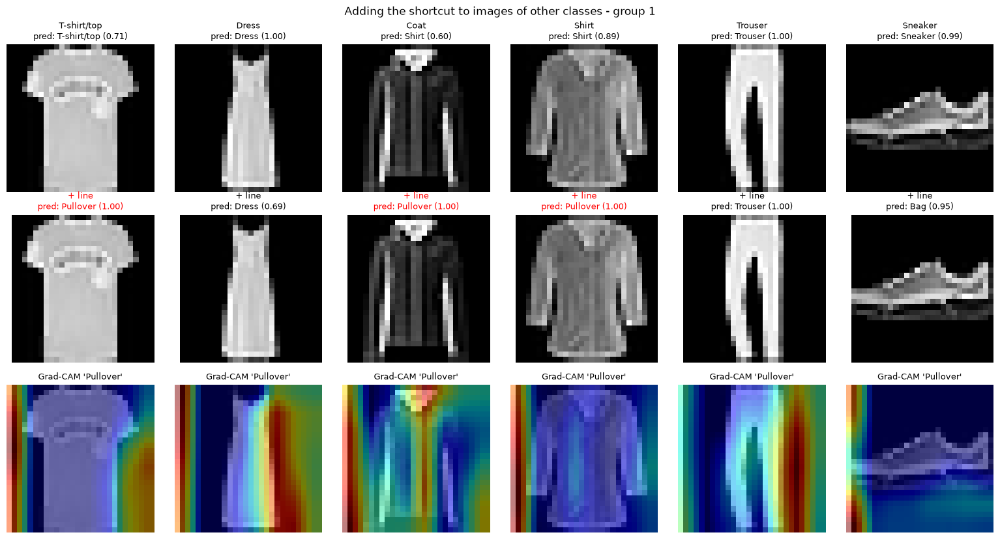

In [21]:
# Test: add the shortcut (a bright 1-pixel line in column 0) to all test images.
# Control: the same line on the right edge (column 27).
def add_line(x, column):
    x = x.clone()
    x[:, :, :, column] = 1.0
    return x


with torch.no_grad():
    pred_left = mystery(add_line(X_fm, 0)).argmax(1)
    pred_right = mystery(add_line(X_fm, 27)).argmax(1)

frac_clean = [(pred_fm[y_fm == c] == c_bad).float().mean().item() for c in range(10)]
frac_left = [(pred_left[y_fm == c] == c_bad).float().mean().item() for c in range(10)]
frac_right = [(pred_right[y_fm == c] == c_bad).float().mean().item() for c in range(10)]

print(f"{'class':12s} {'clean':>7s} {'left line':>10s} {'right line':>11s}   (fraction predicted as {FASHION_CLASSES[c_bad]})")
for c in range(10):
    print(f"{FASHION_CLASSES[c]:12s} {frac_clean[c]:7.3f} {frac_left[c]:10.3f} {frac_right[c]:11.3f}")

print(f"\nOverall accuracy: clean {(pred_fm == y_fm).float().mean():.4f}, "
      f"with left line {(pred_left == y_fm).float().mean():.4f}, "
      f"with right line {(pred_right == y_fm).float().mean():.4f}")
print(f"Other classes predicted as {FASHION_CLASSES[c_bad]}: clean {(pred_fm[other] == c_bad).float().mean():.1%}, "
      f"left line {(pred_left[other] == c_bad).float().mean():.1%}, right line {(pred_right[other] == c_bad).float().mean():.1%}")

x_pos = np.arange(10)
plt.figure(figsize=(11, 4.5))
plt.bar(x_pos - 0.27, frac_clean, 0.27, label="clean")
plt.bar(x_pos, frac_left, 0.27, label="line in column 0 (shortcut)", color="tab:red")
plt.bar(x_pos + 0.27, frac_right, 0.27, label="line in column 27 (control)", color="tab:gray")
plt.xticks(x_pos, FASHION_CLASSES, rotation=45, ha="right")
plt.ylabel(f"Fraction predicted as '{FASHION_CLASSES[c_bad]}'")
plt.legend()
plt.title(f"Effect of the shortcut on every class - group {GROUP_NUMBER}")
plt.tight_layout()
plt.show()

# Examples of other classes with and without the shortcut, with Grad-CAM for the worst class
examples = [torch.where(y_fm == c)[0][0].item() for c in [0, 3, 4, 6, 1, 7]]
x_ex = X_fm[examples]
x_ex_line = add_line(x_ex, 0)
with torch.no_grad():
    p_ex = mystery(x_ex).softmax(1)
    p_ex_line = mystery(x_ex_line).softmax(1)

cam = GradCAM(model=mystery, target_layers=[mystery.conv_layers[3]])
heat_line = cam(input_tensor=x_ex_line, targets=[ClassifierOutputTarget(c_bad)] * len(examples))
cam.activations_and_grads.release()

fig, axes = plt.subplots(3, len(examples), figsize=(2.6 * len(examples), 8.4))
for i in range(len(examples)):
    pc, pl = p_ex[i].argmax().item(), p_ex_line[i].argmax().item()
    axes[0, i].imshow(x_ex[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(f"{FASHION_CLASSES[y_fm[examples[i]]]}\npred: {FASHION_CLASSES[pc]} ({p_ex[i, pc]:.2f})", fontsize=9)
    axes[1, i].imshow(x_ex_line[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[1, i].set_title(f"+ line\npred: {FASHION_CLASSES[pl]} ({p_ex_line[i, pl]:.2f})", fontsize=9,
                         color="red" if pl == c_bad else "black")
    axes[2, i].imshow(x_ex_line[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[2, i].imshow(heat_line[i], cmap="jet", alpha=0.5)
    axes[2, i].set_title(f"Grad-CAM '{FASHION_CLASSES[c_bad]}'", fontsize=9)
    for ax in axes[:, i]:
        ax.axis("off")
fig.suptitle(f"Adding the shortcut to images of other classes - group {GROUP_NUMBER}")
plt.tight_layout()
plt.show()

**Your answers:**

a) The model reaches a clean test accuracy of 0.792, but the per-class accuracy shows that the problem is concentrated in Pullover, which is classified correctly in only 4.8% of the cases (the other classes are between 0.590 and 0.975). Most pullovers are predicted as Shirt (555) or Coat (364). This suggests that the model learned to recognise pullovers by the shortcut instead of their shape, so on clean images it falls back to the most similar garments.

Grad-CAM on clean pullovers does not focus on the garment, but often on the border of the image, which was a first sign that the model looks at the edges. The mean signed gradient confirms this: 16.0% of the positive gradient of Pullover lies in the three leftmost columns (10.7% of the image), compared to 0.9% for Coat. Adding a bright line at every column and row shows that a vertical line in columns 0–3 turns about 50% of the other images into Pullover, while a line anywhere else has practically no effect. The shortcut is therefore a bright vertical line at the left edge of the image.

To test this, we added a 1-pixel line in column 0 to all test images. The Pullover accuracy rises from 0.048 to 1.000, 49.0% of the other images become Pullover, and the overall accuracy drops to 0.269. The same line on the right edge has no effect (accuracy 0.796), and with the line Grad-CAM moves to the left edge in all examples. Interestingly, mainly upper-body garments are affected (T-shirt/top 98.8%, Coat 100%, Shirt 99.5%, Dress 91.8%), while footwear stays almost unchanged (Sneaker 1.2%, Ankle boot 1.9%). The model thus learned "top + line on the left = pullover": it still uses the shape to recognise a top, but relies on the line instead of the real features to distinguish pullovers from shirts and coats.

## Q6) Reflection

a) **[Basic]** Which method from this lab would you trust most for a medical image? Use your own results to explain why.

b) **[Regular]** Assess occlusion, Grad-CAM and DeepSHAP on completeness, comprehensibility and stability.

**Your answers:**

a) For a medical image we would trust Grad-CAM the most, checked with occlusion. In the sanity check (Q3c) the Grad-CAM map changed completely when the weights were randomised, so it really depends on what the model learned. In the deletion test (Q3e) removing the Grad-CAM regions made the baseball probability drop from 0.51 to about 0.11 after 55% of the pixels, much faster than for saliency and Integrated Gradients. In Q5 it also moved to the shortcut line as soon as it was added, which matters because shortcuts such as rulers or text markers are a known problem in medical images.

However, Grad-CAM has a low resolution and on the clean pullovers in Q5 it highlighted the image border, so it can also be misleading. Occlusion is a useful check because it directly measures the effect of removing a region, although the result depends on the patch (Q1d). DeepSHAP is the least suitable, since its result changed strongly with the background (Q4c) and it is unclear what a neutral reference image would be for a medical scan.

b)
- Occlusion: Not very complete, because it only measures the effect of removing one region at a time and misses interactions between regions. It is easy to understand ("what happens if we hide this part?"), but the maps are blocky. Its stability is low with respect to the settings: in Q1c the 16, 32 and 64 pixel windows gave clearly different maps (and took 43 s, 9.3 s and 2.0 s), and in Q1d the black, grey and blurred patches moved the hotspots.
- Grad-CAM: The least complete, since it only uses the last convolutional layer, shows only positive evidence and is normalised, so it shows where the model looks but not how much this contributes. It is the easiest to understand (Q3d) and can separate several objects in one image (Q3b). It is fairly stable because of its low resolution, while still changing with the model weights as it should (Q3c).
- DeepSHAP: The most complete, because the SHAP values add up to the difference between the prediction and the expected output over the background, and show both evidence for (red) and against (blue) each class. It is harder to understand, as it gives a pixel map for every class relative to a background. Its stability is low: for the same digit 8 the maps differed by a mean absolute difference of 0.013–0.021 between backgrounds, and the important middle crossing with the black background was no longer important with the digit-1 background (Q4c).

Overall, no method scores well on all three criteria, so an explanation should be combined with a test, such as the deletion test in Q3e or adding the shortcut in Q5.